# Phase Shift: the physics behind the game

This notebook walks through the three levels of **Phase Shift** with plain Qiskit, then shows the
"amplitude arrows" the game draws, and how to run the same circuits on IonQ's simulator.

* On **Qollab** the game itself is the web page (`index.html` + `main.js`); this notebook is a
  companion for teachers and developers. It runs with Qiskit's built-in simulator, no extras needed.
* Locally: `pip install -r requirements-dev.txt`, then open this notebook from the repository root.

In [1]:
import math, os, sys
sys.path.insert(0, os.path.abspath(".."))  # the repository root, when run from notebooks/
from qiskit import QuantumCircuit
from qiskit.providers.basic_provider import BasicSimulator
from phaseshift import circuits, execution, paths
from phaseshift.levels import get_level, mystery_phase

sim = BasicSimulator()
def run(qc, shots=2000):
    return execution.to_probabilities(execution.run_circuit(sim, qc, shots=shots, seed=7))

## 1. Superposition: H splits the qubit into two paths
Measuring right after a Hadamard gives 50/50.

In [2]:
qc = QuantumCircuit(1, 1)
qc.h(0)
qc.measure(0, 0)
print(qc.draw())
run(qc)

     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


{'0': 0.5065, '1': 0.4935}

## 2. Level 1, *Invisible Ink*: a phase alone is invisible
Add a phase gate P(φ) after the split. Whatever φ is, the counts stay at 50/50, because a measurement only sees the
length of each amplitude arrow, and P(φ) only rotates one of them. (The simulator seed is fixed, so the counts
come out identical to the last shot: the phase changes nothing a measurement can see.)

In [3]:
lvl = get_level("invisible-ink")
for phi in (0, 45, 90, 180, 270):
    probs = run(circuits.build_circuit(lvl, {"phi": phi, "recombine": False}))
    print(f"phi = {phi:3d}°  ->  P(|1>) = {probs['1']:.3f}")

phi =   0°  ->  P(|1>) = 0.493
phi =  45°  ->  P(|1>) = 0.493
phi =  90°  ->  P(|1>) = 0.493
phi = 180°  ->  P(|1>) = 0.493
phi = 270°  ->  P(|1>) = 0.493


### Recombine the paths with a second H: now the phase decides
Theory: P(|1⟩) = sin²(φ/2). The sweep below runs the circuit for every dial position.

In [4]:
rows = []
for k in range(25):
    phi = 15 * k
    measured = run(circuits.build_circuit(lvl, {"phi": phi % 360, "recombine": True}))["1"]
    rows.append((phi, measured, math.sin(math.radians(phi) / 2) ** 2))
for phi, m, t in rows[::3]:
    print(f"phi = {phi:3d}°  measured {m:.3f}   theory {t:.3f}")

phi =   0°  measured 0.000   theory 0.000
phi =  45°  measured 0.144   theory 0.146
phi =  90°  measured 0.493   theory 0.500
phi = 135°  measured 0.855   theory 0.854
phi = 180°  measured 1.000   theory 1.000
phi = 225°  measured 0.855   theory 0.854
phi = 270°  measured 0.493   theory 0.500
phi = 315°  measured 0.144   theory 0.146
phi = 360°  measured 0.000   theory 0.000


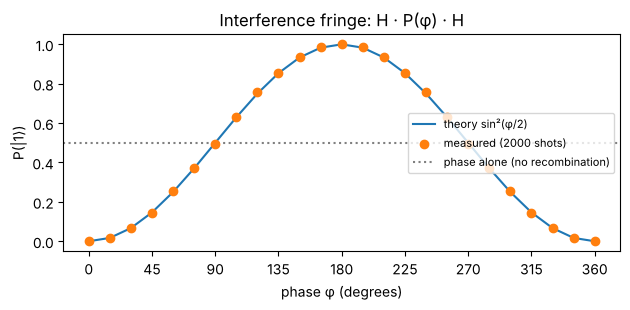

In [5]:
%matplotlib inline
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot([r[0] for r in rows], [r[2] for r in rows], label="theory sin²(φ/2)", color="#1f77b4")
ax.scatter([r[0] for r in rows], [r[1] for r in rows], label="measured (2000 shots)", color="#ff7f0e", zorder=3)
ax.axhline(0.5, ls=":", color="gray", label="phase alone (no recombination)")
ax.set_xlabel("phase φ (degrees)"); ax.set_ylabel("P(|1⟩)"); ax.set_xticks(range(0, 361, 45))
ax.legend(loc="center right", fontsize=8); ax.set_title("Interference fringe: H · P(φ) · H")
fig.tight_layout()
plt.show()

## 3. The arrows: classical vs quantum
`phaseshift.paths` enumerates every path through the circuit and its amplitude. Quantum probability = |sum of arrows|²;
classical = sum of |arrow|². The difference is the interference term the game shows for each outcome.

In [6]:
qc = circuits.build_circuit(lvl, {"phi": 180, "recombine": True}, measure=False)
for o in paths.analyze(qc)["outcomes"]:
    arrows = ", ".join(f"{a['arm']}: {complex(a['re'], a['im']):.2f}" for a in o["arrows"])
    print(f"{o['label']}: arrows [{arrows}]  classical {o['classical']:.2f}  quantum {o['theory']:.2f}  interference {o['interference']:+.2f}")

|0⟩: arrows [upper: 0.50+0.00j, lower: -0.50+0.00j]  classical 0.50  quantum 0.00  interference -0.50
|1⟩: arrows [upper: 0.50+0.00j, lower: 0.50-0.00j]  classical 0.50  quantum 1.00  interference +0.50


## 4. Level 2, *Dark Port*: measuring a hidden phase
A mystery phase θ sits on the lower path. P(|1⟩) = sin²((θ + φ)/2), so one measurement gives |θ + φ| and a second
one tells the sign. Here is the two-run strategy the par is based on.

In [7]:
dark = get_level("dark-port"); seed = 2026
p1 = run(circuits.build_circuit(dark, {"phi": 0}, seed=seed))["1"]
delta = math.degrees(2 * math.asin(math.sqrt(p1)))
print(f"run 1: phi = 0 -> P(|1>) = {p1:.3f}  =>  leftover phase ≈ ±{delta:.0f}°")
guess = (-round(delta / 15) * 15) % 360
p2 = run(circuits.build_circuit(dark, {"phi": guess}, seed=seed))["1"]
if p2 > 0.05:
    guess = (round(delta / 15) * 15) % 360
    p2 = run(circuits.build_circuit(dark, {"phi": guess}, seed=seed))["1"]
print(f"answer: phi = {guess}° -> P(|1>) = {p2:.3f}   (the hidden theta was {mystery_phase(seed)}°)")

run 1: phi = 0 -> P(|1>) = 0.372  =>  leftover phase ≈ ±75°
answer: phi = 285° -> P(|1>) = 0.000   (the hidden theta was 75°)


## 5. Level 3, *Which-Path Eraser*: interference moves into correlations

In [8]:
er = get_level("eraser")
for eraser in (False, True):
    qc = circuits.build_circuit(er, {"phi": 180, "eraser": eraser})
    probs = run(qc)
    disagree = probs["01"] + probs["10"]
    photon = paths.marginal(probs, 0, 2)["1"]
    print(f"eraser {'on ' if eraser else 'off'}: P(disagree) = {disagree:.3f}, photon alone P(1) = {photon:.3f}")
print(circuits.build_circuit(er, {"phi": 180, "eraser": True}).draw())

eraser off: P(disagree) = 0.502, photon alone P(1) = 0.518
eraser on : P(disagree) = 1.000, photon alone P(1) = 0.506
     ┌───┐     ┌──────┐┌───┐┌─┐
q_0: ┤ H ├──■──┤ P(π) ├┤ H ├┤M├
     └───┘┌─┴─┐└┬───┬─┘└┬─┬┘└╥┘
q_1: ─────┤ X ├─┤ H ├───┤M├──╫─
          └───┘ └───┘   └╥┘  ║ 
c: 2/════════════════════╩═══╩═
                         1   0 


## 6. Running on IonQ's simulator

**On Qollab** you do not create a backend: press **Run**, pick IonQ's simulator in *Select QPU*, and the platform
passes a `backend` object to the page; `phaseshift.api.run_level(backend, ...)` submits one single-circuit job.

**Locally** (outside Qollab) use `qiskit-ionq` with your own key: `export IONQ_API_KEY=...`. The cell below only
runs if a key is set. `noise_model="aria-1"` or `"forte-1"` adds IonQ's hardware noise model to the simulator.

In [9]:
if os.environ.get("IONQ_API_KEY"):
    ionq = execution.ionq_backend()  # or execution.ionq_backend(noise_model="aria-1")
    qc = circuits.build_circuit(lvl, {"phi": 180, "recombine": True})
    print(execution.to_probabilities(execution.run_circuit(ionq, qc, shots=1000)))
else:
    print("IONQ_API_KEY not set: skipping the IonQ cell. On Qollab, select IonQ in 'Select QPU' instead.")

IONQ_API_KEY not set: skipping the IonQ cell. On Qollab, select IonQ in 'Select QPU' instead.


## 7. Same thing through the game API
This is the exact call the web page makes (with `where="backend"` it would use Qollab's selected backend).

In [10]:
from phaseshift import api
res = api.run_level(None, "eraser", {"phi": 180, "eraser": True}, {"where": "local", "shots": 1000})
print(res["feedback"]["headline"]); print(res["feedback"]["detail"])

Information erased. You solved the level!
The CNOT had copied 'which path?' into the detector, which killed the interference. Your eraser H sent both paths to both detector readings, so the paths became indistinguishable again and interfered. With φ = 180° (π) photon and detector disagreed 100% of the time. The photon on its own is still 50/50: the interference pattern lives in the correlation.
